# Lecture 1 vibes

In [1]:
%load_ext autoreload
%autoreload 2

In [19]:
import numpy as np
from numpy.linalg import norm
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Circular Restricted 3-body Problem

In [11]:
MU_PLUTO = 870.9
MU_CHARON = 101.0
MU_TOTAL = MU_CHARON + MU_PLUTO

R_PLUTO_CHARON = 19640 
R_BARY_PLUTO = MU_CHARON / MU_TOTAL * R_PLUTO_CHARON
R_BARY_CHARON = R_PLUTO_CHARON - R_BARY_PLUTO
print(f"r_pluto: {R_BARY_PLUTO}")
print(f"r_charon: {R_BARY_CHARON}")
assert R_BARY_CHARON + R_BARY_PLUTO == R_PLUTO_CHARON
t_orb = 2*np.pi * np.sqrt(R_PLUTO_CHARON**3 / MU_TOTAL)
W_S = 2*np.pi / t_orb


print(f"Period: {t_orb}s")

r_pluto: 2040.9918715917274
r_charon: 17599.008128408273
Period: 554729.5518605391s


In [25]:
def two_body_pluto_charon(t,s):
    r_bp, v_bp, r_bc, v_bc = s[0:2], s[2:4], s[4:6], s[6:8]
    r_pc = r_bc - r_bp
    
    a_p = MU_CHARON / norm(r_pc)**3 * r_pc
    a_c = MU_PLUTO / norm(-r_pc)**3 * (-r_pc)
    
    return np.concatenate((v_bp, a_p, v_bc, a_c))

In [52]:
state0 = np.array([
    -R_BARY_PLUTO, 0, 0, -R_BARY_PLUTO*W_S,
    R_BARY_CHARON, 0, 0, R_BARY_CHARON*W_S,
])

ts = np.linspace(0, 5e5, 100000)

result = solve_ivp(two_body_pluto_charon, (ts[0], ts[-1]), state0, t_eval=ts, rtol=1e-10,atol=1e-12)
print(result.y.shape)

(8, 100000)


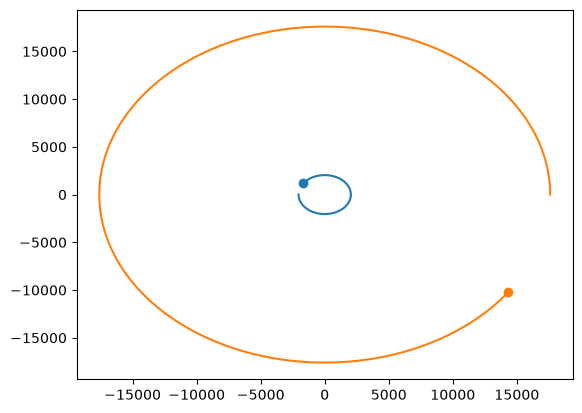

In [53]:
plt.plot(result.y[0],result.y[1])
plt.plot(result.y[4],result.y[5])
plt.scatter([result.y[0,-1]],[result.y[1,-1]])
plt.scatter([result.y[4,-1]],[result.y[5,-1]])